# Phase 3, part 3: prescribed winds and wind uncertainty

**Questions this notebook answers.**
1. How large must the outer model domain be when the wind turns around (EXP-021, F-031)?
2. How much does a wrong wind direction or speed hurt the source estimate, and can we detect it (EXP-019, F-029)?

Everything is **synthetic**. Every wind is **prescribed by hand**. No wind is derived from terrain or from weather data.
Docs: `docs/winds.md`, `docs/phase3-findings.md`. Evidence: `results/phase3-winds-toy/`, `results/phase3-winds-converged/`, `results/phase3-wind-error-toy/production/`.

## What this shows / does not show

**Shows**
* How to build divergence-free toy winds from a stream function, and what they look like.
* The outer half-width needed for less than 1 % exposure error is about `U T / 2` for reversal scenarios (40 km here), set by the return window.
* A wind-direction error of 5 degrees raises field error by 1.4 to 1.6 times and 30 degrees by 3.5 to 3.8 times (fixed wrong wind). From 10 degrees it outweighs the sensor-count effect.
* chi2/dof detects a wrong wind. The identifiability flags cannot, because they do not use the data.

**Does not show**
* Any real wind or terrain effect. Terrain-to-wind coupling was not built.
* That an ensemble estimator is generally better. It helps only when the true wind is near an ensemble member, and its intervals are overconfident otherwise.
* Results at Belauri scale. The wind-error study is a toy domain with 32 test cases per condition.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path("..").resolve()          # notebooks run with cwd = notebooks/
R = ROOT / "results"
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

def show(path, width=760):
    """Show a saved PNG from results/. Skips quietly if the file is missing."""
    p = Path(path)
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        print("missing:", p.relative_to(ROOT))

def load(path):
    p = Path(path)
    if not p.exists():
        print("missing:", p.relative_to(ROOT)); return None
    return pd.read_csv(p)

from pravah.config import Domain
from pravah import winds

## 1. Prescribed wind vs terrain-derived wind

A **terrain-derived** wind would come from a flow model that sees the DEM (pressure, blocking, stability). We do not have one.
A **prescribed** wind is written down by hand as a formula. It can be turned around, bent or made to circulate. It shows what the transport model does with such a wind. It does not say the wind would occur.

## 2. Stream function

A 2-D flow with no sources or sinks (divergence free) can be written with a scalar `psi` (m^2/s): `u = d psi / dy`, `v = - d psi / dx`.
The solver stores `psi` at cell corners and builds face fluxes from differences. So the discrete divergence is zero to rounding error by construction.
Uniform wind `(u, v)` corresponds to `psi = u y - v x`. Adding a Gaussian bump to `psi` bends the wind around it.
`winds.face_divergence` checks it.

Text(0.5, 0.98, 'Prescribed wind fields (grey = streamlines). Not terrain-derived.')

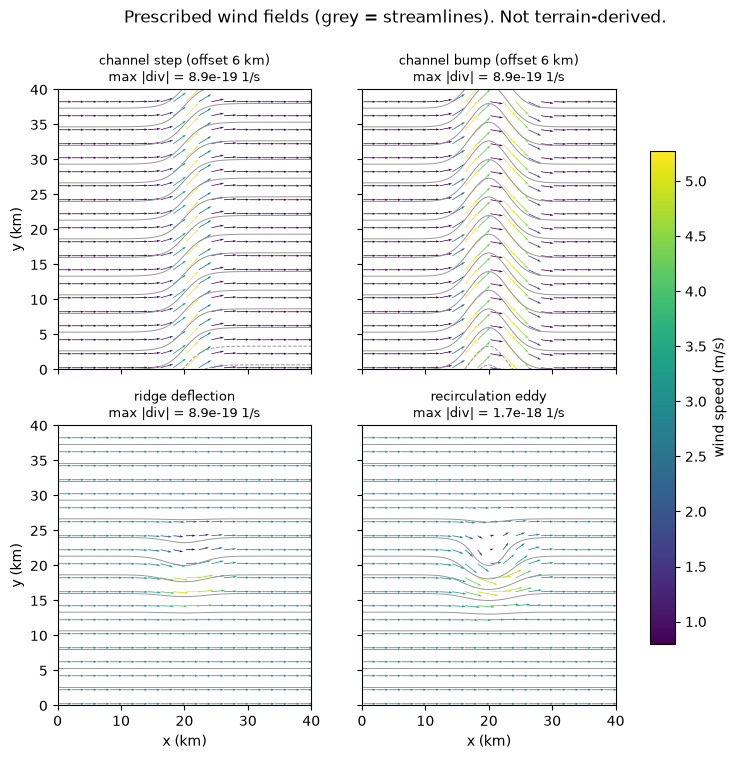

In [2]:
dom = Domain(lx=40_000.0, ly=40_000.0, nx=80, ny=80)         # 40 km x 40 km, 500 m cells

def centre_wind(seg, d=dom):
    psi = seg.psi
    uf = (psi[1:, :] - psi[:-1, :]) / d.dy; vf = -(psi[:, 1:] - psi[:, :-1]) / d.dx
    return 0.5 * (uf[:, 1:] + uf[:, :-1]), 0.5 * (vf[1:, :] + vf[:-1, :]), psi

cases = {
    "channel step (offset 6 km)": winds.deflected_channel(dom, 3.0, 20_000, 3_000, 6_000, "step")[0],
    "channel bump (offset 6 km)": winds.deflected_channel(dom, 3.0, 20_000, 3_000, 6_000, "bump")[0],
    "ridge deflection": winds.ridge_deflection(dom, 3.0, 0.0, (20_000, 20_000), 3_000, 4_000)[0],
    "recirculation eddy": winds.recirculation_eddy(dom, 3.0, 0.0, (20_000, 20_000), 3_000, 12_000)[0],
}
xc = (np.arange(dom.nx) + 0.5) * dom.dx / 1000; yc = (np.arange(dom.ny) + 0.5) * dom.dy / 1000
fig, axs = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
for ax, (name, seg) in zip(axs.ravel(), cases.items()):
    uu, vv, psi = centre_wind(seg)
    ax.contour(np.arange(dom.nx + 1) * dom.dx / 1000, np.arange(dom.ny + 1) * dom.dy / 1000, psi, 18, colors="0.6", linewidths=0.7)
    sp = np.hypot(uu, vv)
    q = ax.quiver(xc[::4], yc[::4], uu[::4, ::4], vv[::4, ::4], sp[::4, ::4], cmap="viridis", scale=60)
    ax.set_title(f"{name}\nmax |div| = {np.abs(winds.face_divergence(dom, psi)).max():.1e} 1/s", fontsize=9)
for ax in axs[1]: ax.set_xlabel("x (km)")
for ax in axs[:, 0]: ax.set_ylabel("y (km)")
fig.colorbar(q, ax=axs, label="wind speed (m/s)", shrink=0.8)
fig.suptitle("Prescribed wind fields (grey = streamlines). Not terrain-derived.", y=0.98)

Builders in `src/pravah/winds.py`: `steady_uniform`, `delayed_reversal` (the whole wind flips sign at time `t_r`), `ridge_deflection`, `recirculation_eddy`, `deflected_channel`, and `segments_from_series` (the only entry point for external data, e.g. ERA5; not used yet).
The winds are piecewise constant in time. Coordinates are metres from the south-west corner of the domain.

The saved schematic from EXP-018:

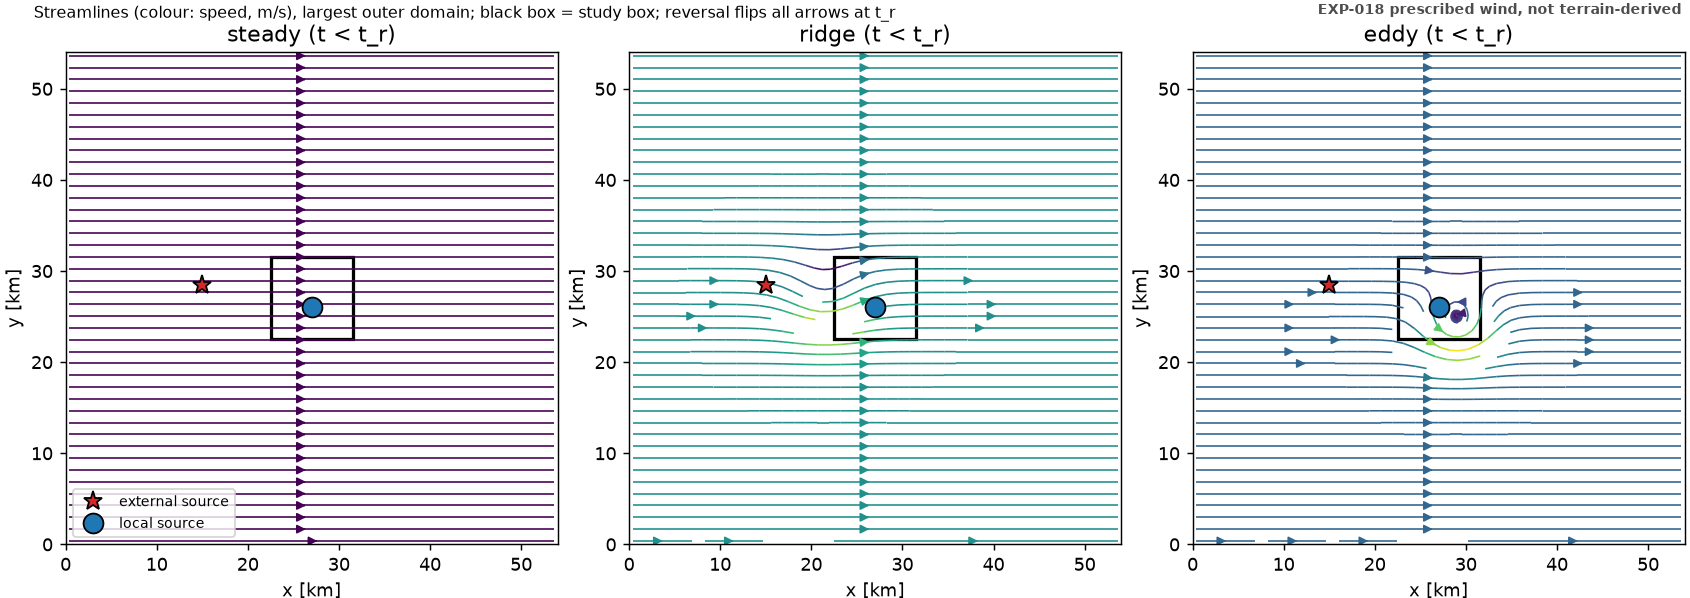

In [3]:
show(R / "phase3-winds-toy" / "fig1_wind_schematic.png", 760)

## 3. EXP-021: domain size and the return window (F-031)

Question. The model domain has open boundaries. If the wind reverses, mass that left returns. A domain that is too small loses mass that would come back, and the exposure inside the study area is wrong.
Setting: reversal at time `T_r`. The total advection distance is `U T = 86.4 km` (`advection_distance_m` in `checks.json`).
Half-widths of 20, 40, 80 and 175 km (reference). The 175 km domain is converged: the two largest differ by about 1e-16 in exposure.

In [4]:
W = R / "phase3-winds-converged"
vs = load(W / "vs_reference.csv"); chk = json.load(open(W / "checks.json"))
print({k: chk[k] for k in ["advection_distance_m", "reference_half_width_m", "worst_exposure_rel_diff_two_largest", "converged", "closure_ok"]})
t = vs[["scenario", "t_r_s", "half_width_m", "ext_exposure_rel_to_ref"]].copy()
t["ext_exposure_rel_to_ref (%)"] = 100 * t.pop("ext_exposure_rel_to_ref")
t.pivot_table(index=["scenario", "t_r_s"], columns="half_width_m", values="ext_exposure_rel_to_ref (%)", dropna=False).dropna(how="all").round(3)

{'advection_distance_m': 86400.0, 'reference_half_width_m': 175000.0, 'worst_exposure_rel_diff_two_largest': 1.3555702168349213e-16, 'converged': True, 'closure_ok': True}


half_width_m           2e+04     4e+04     8e+04     1.75e+05
scenario     t_r_s                                           
channel_bump NaN             -0         0         0         0
channel_step NaN             -0        -0         0         0
reversal     1.8e+04     -6.317        -0         0         0
             2.25e+04    -16.81    -0.054         0         0
             2.7e+04     -7.071    -0.096         0         0
steady       NaN             -0        -0         0         0
vortex       NaN             -0         0         0         0

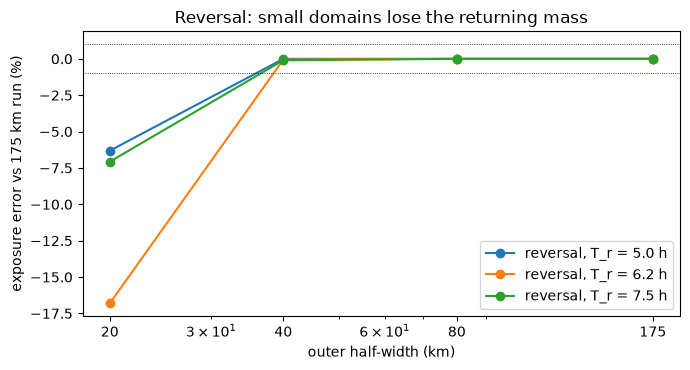

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for tr, g in vs[vs.scenario == "reversal"].groupby("t_r_s"):
    ax.plot(g.half_width_m / 1000, 100 * g.ext_exposure_rel_to_ref, "o-", label=f"reversal, T_r = {tr/3600:.1f} h")
ax.axhline(-1, color="k", lw=0.6, ls=":"); ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set_xscale("log"); ax.set_xticks([20, 40, 80, 175]); ax.set_xticklabels(["20", "40", "80", "175"])
ax.set_xlabel("outer half-width (km)"); ax.set_ylabel("exposure error vs 175 km run (%)"); ax.legend()
ax.set_title("Reversal: small domains lose the returning mass"); fig.tight_layout()

**Return window.** After the reversal at `T_r`, the plume is carried back the way it came. Mass that crossed the outer boundary before `T_r` can only return if the boundary is within reach.
The farthest the air can go and come back is about `U T / 2`, because it has to travel out and back inside the total time `T`. That gives about 43 km for `U T = 86.4 km`, so the 40 km domain gives under 1 % error and 20 km does not.
Longer simulation time `T` means a larger needed domain. The steady and channel scenarios have no returning mass. For them the box size matters only through mass leaving east (`leave_east_frac`).
An earlier explanation (U and lambda) was refuted by a control, and an earlier result with an unconverged reference was superseded (F-024 -> F-027 -> F-031).

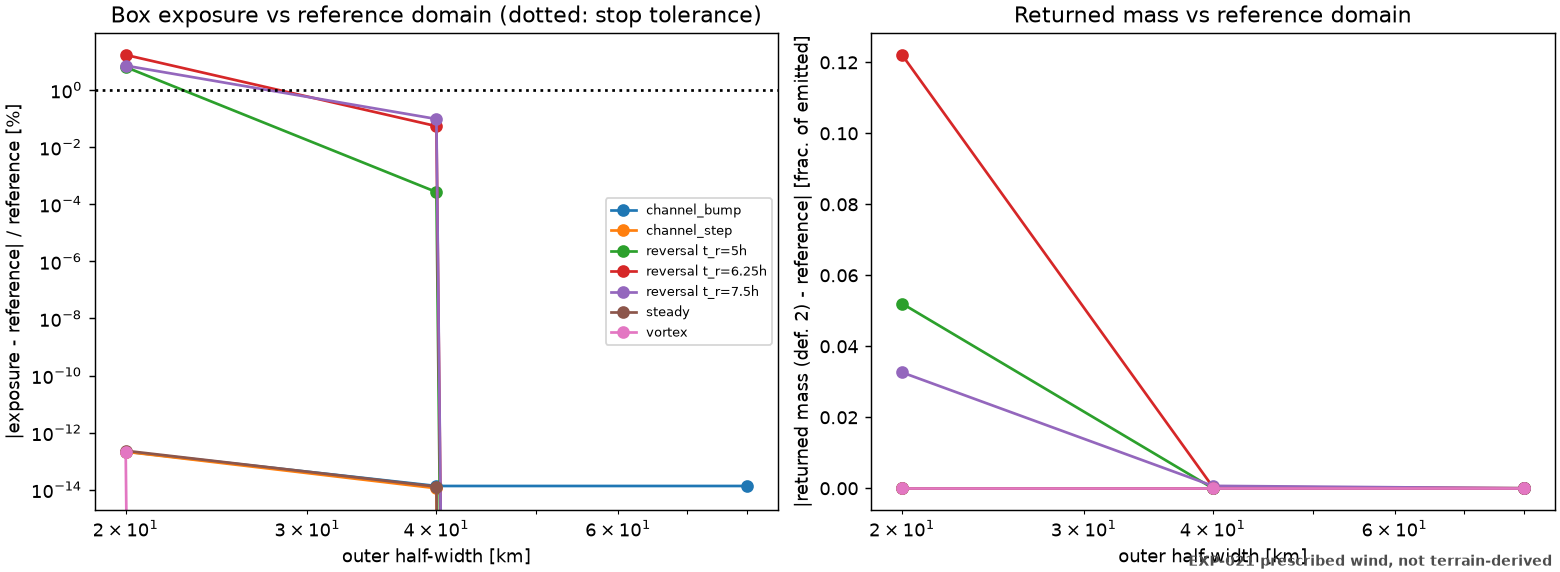

In [6]:
show(W / "fig1_convergence.png", 760)

**Scenario effects (F-031).** Channel offset gives about -43 % exposure at the receptor. That is a placement effect of moving the plume, not a transport effect.
The vortex gives -10 %. Reversals raise exposure by +8 % to +42 %. Returned mass is good to about 10 % (mesh dependence).

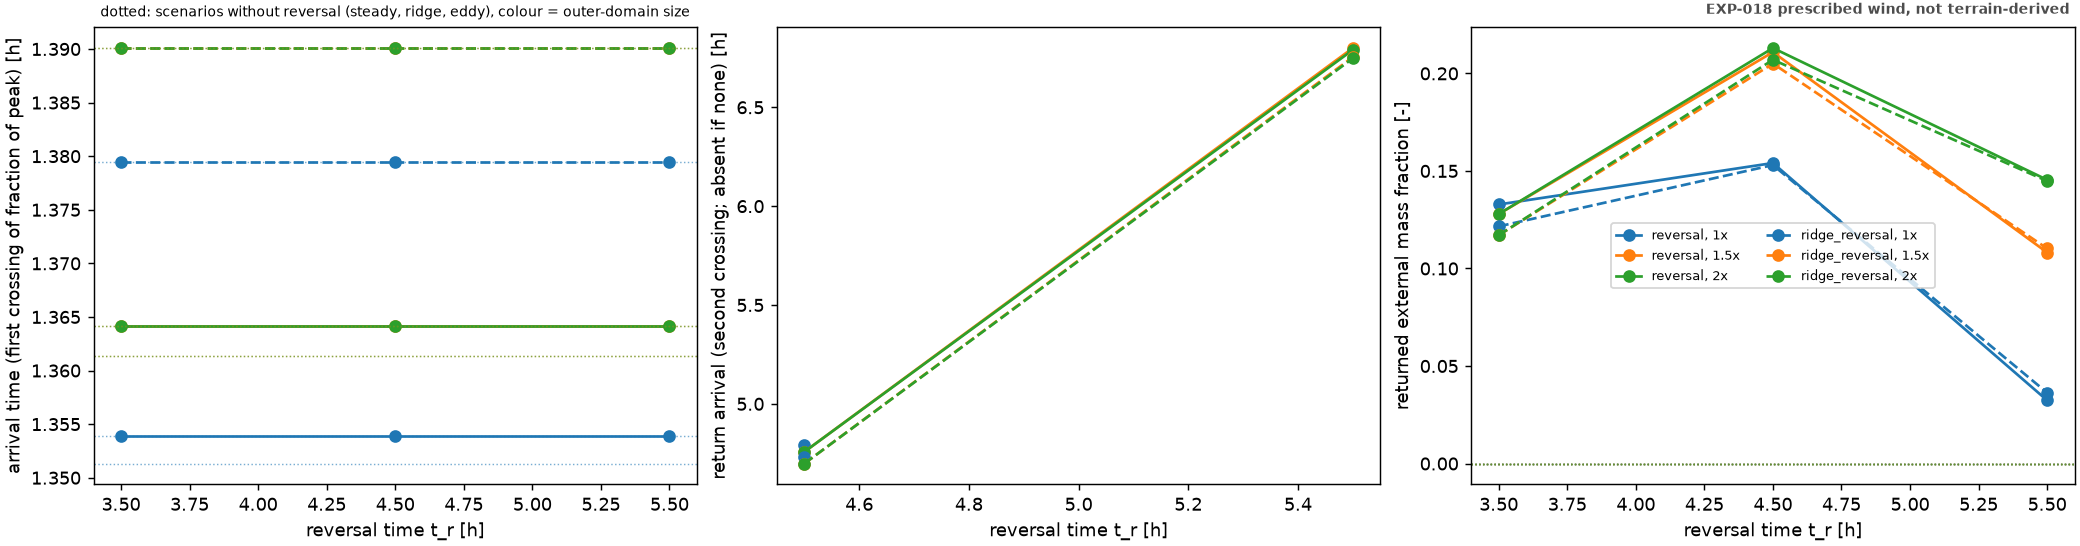

In [7]:
show(R / "phase3-winds-toy" / "fig2_arrival_returned_vs_tr.png", 760)

## 4. EXP-019: wind-error response (F-029)

Setup. A synthetic domain with 3 local sources and one external (inflow) basis. The **true** wind is rotated by up to 30 degrees and/or scaled by up to 30 %.
Three estimators see data from the true wind:
* **A**: the model uses the true wind (known-wind baseline).
* **B**: the model uses the nominal (wrong) wind and fits amplitudes only.
* **C**: the model averages over an ensemble of 15 declared winds (posterior weights from the data).

Vector error is `|du| / |u|`. A rotation by `dtheta` at constant speed gives `2 sin(dtheta/2)`: 0.087 (5 degrees), 0.174 (10), 0.261 (15), 0.518 (30).
Metric: RMSE of the total concentration field on 32 test cases (same relative units for all curves). Intervals are **percentile bootstraps over the 32 test cases**.
Budgets 3, 5 and 8 sensors; the curves below use budget 3. The same wind is applied at every case, so cases do not vary the wind.

B / A field-error ratio by direction error (degrees):
deg
0        1
5     1.23
10    1.67
15    2.23
30     2.3
-5    1.38
-10   1.78
-15   1.95
-30   2.53


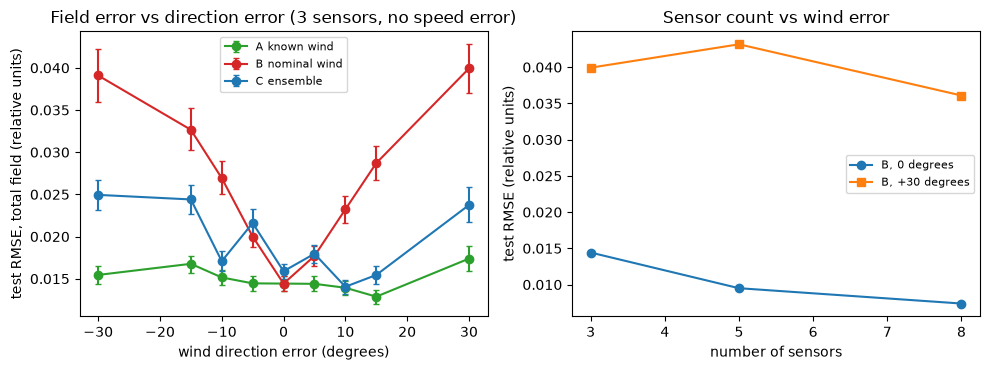

In [8]:
T = R / "phase3-wind-error-toy" / "production" / "tables"
rc = load(T / "response_curves.csv"); cal = load(T / "calibration.csv")
d = rc[(rc.metric == "rmse_total") & (rc.budget == 3) & (rc.speed_pct == 0)]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for strat, col in zip("ABC", ["tab:green", "tab:red", "tab:blue"]):
    g = d[d.strategy == strat].sort_values("deg")
    axs[0].errorbar(g.deg, g["mean"], yerr=[g["mean"] - g.ci_lo, g.ci_hi - g["mean"]], marker="o", color=col, capsize=2,
                    label={"A": "A known wind", "B": "B nominal wind", "C": "C ensemble"}[strat])
axs[0].set_xlabel("wind direction error (degrees)"); axs[0].set_ylabel("test RMSE, total field (relative units)")
axs[0].set_title("Field error vs direction error (3 sensors, no speed error)"); axs[0].legend(fontsize=8)
d8 = rc[(rc.metric == "rmse_total") & (rc.deg == 0) & (rc.speed_pct == 0) & (rc.strategy == "B")].sort_values("budget")
b0 = rc[(rc.metric == "rmse_total") & (rc.deg == 30) & (rc.strategy == "B") & (rc.speed_pct == 0)].sort_values("budget")
axs[1].plot(d8.budget, d8["mean"], "o-", label="B, 0 degrees"); axs[1].plot(b0.budget, b0["mean"], "s-", label="B, +30 degrees")
axs[1].set_xlabel("number of sensors"); axs[1].set_ylabel("test RMSE (relative units)"); axs[1].set_title("Sensor count vs wind error"); axs[1].legend(fontsize=8)
fig.tight_layout()
ratio = (d[d.strategy == "B"].set_index("deg")["mean"] / d[(d.strategy == "A")].set_index("deg")["mean"])
print("B / A field-error ratio by direction error (degrees):"); print(ratio.round(2).to_string())

This one-budget slice gives B/A of 1.2 to 1.4 at 5 degrees and 2.3 to 2.5 at 30 degrees. F-029 reports 1.4 to 1.6 and 3.5 to 3.8, pooled over budgets and layout types with its own baseline definition, so the numbers differ. Use F-029 for the claim. The right panel lets you compare the wind-error effect with the sensor-count effect.
The saved figure from the run:

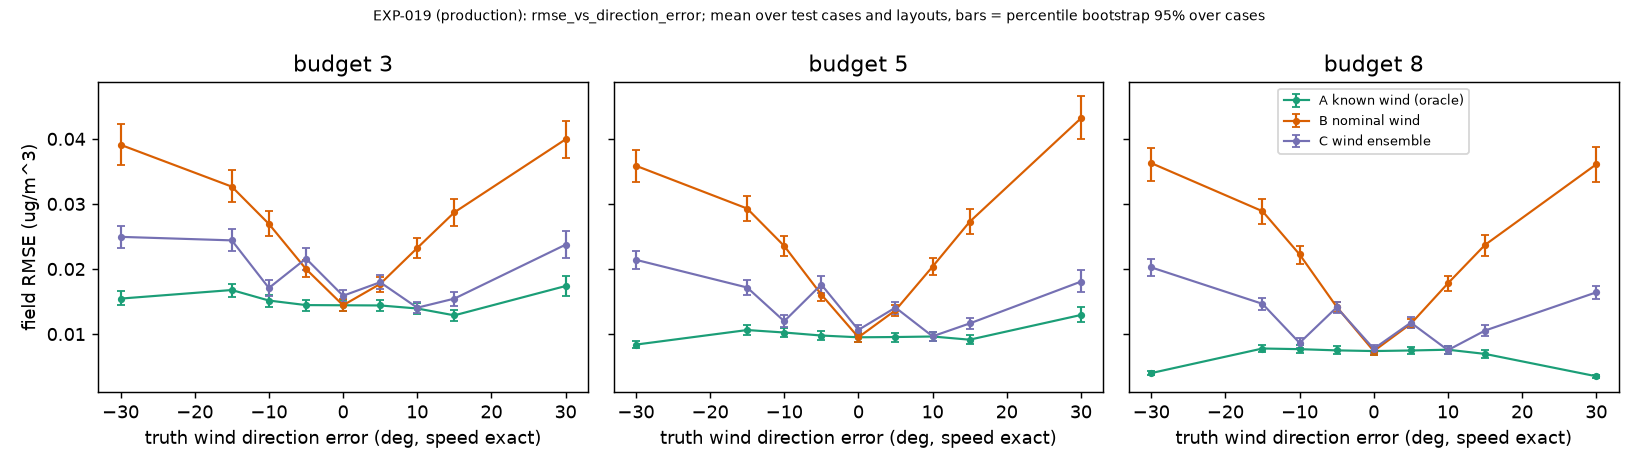

In [9]:
show(T.parent / "figures" / "rmse_vs_direction_error.png", 760)

### chi2/dof, flags and coverage

`chi2/dof` is the data misfit divided by the degrees of freedom, with known noise. It is about 1 when the model is right. Identifiability flags look only at the nominal operator (columns), not at the data.
Coverage is the fraction of true values inside the 90 % interval (target 0.90). It is already 0.72 at zero wind error, so the intervals are not calibrated even without a wind error.

In [10]:
z = cal[(cal.speed_pct == 0)].sort_values(["strategy", "deg"])
z.pivot_table(index="deg", columns="strategy", values=["chi2_per_dof", "frac_flagged", "cov90"]).round(2)

chi2_per_dof            cov90           frac_flagged          
strategy            A     B    C     A    B    C            A    B    C
deg                                                                    
-30              1.02 13.09 2.31  0.71 0.13 0.26         0.33 0.52 0.36
-15              1.02  6.29 1.44  0.68 0.18  0.4         0.42 0.52 0.39
-10              1.02  3.46 1.01  0.69 0.23 0.74         0.42 0.52 0.43
-5               1.02  1.61 1.38  0.71 0.36 0.46         0.48 0.52 0.46
0                1.01  1.01 1.01  0.72 0.72 0.76         0.52 0.52 0.52
5                1.01   1.5  1.3  0.71 0.34  0.5         0.48 0.52  0.5
10               1.02   2.8 1.01  0.71 0.23 0.75         0.52 0.52  0.5
15               1.02  4.71 1.21   0.7 0.18 0.52         0.53 0.52 0.46
30               1.02 13.67 2.51  0.71 0.12 0.35         0.48 0.52 0.43

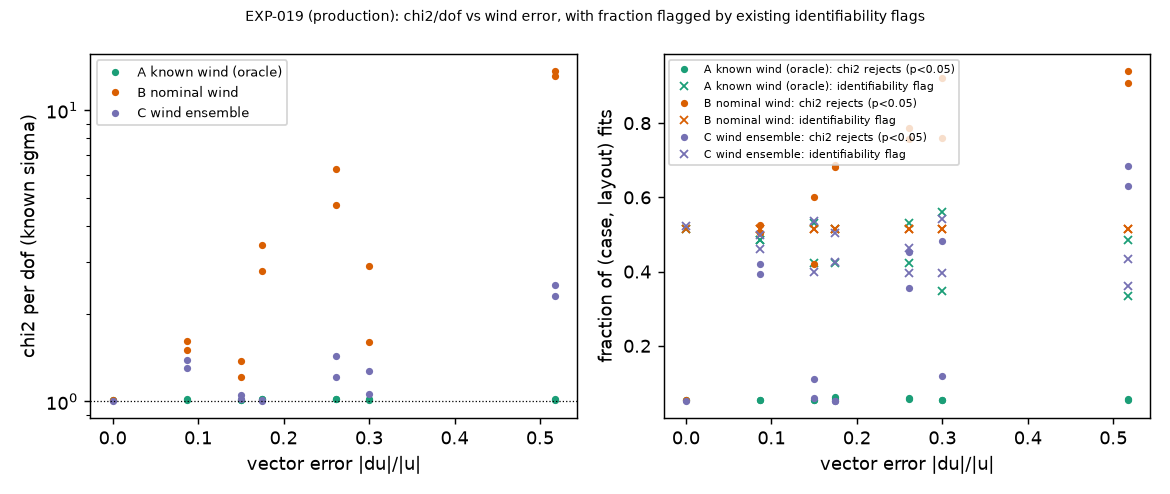

In [11]:
show(T.parent / "figures" / "chi2_and_flags_vs_vector_error.png", 760)

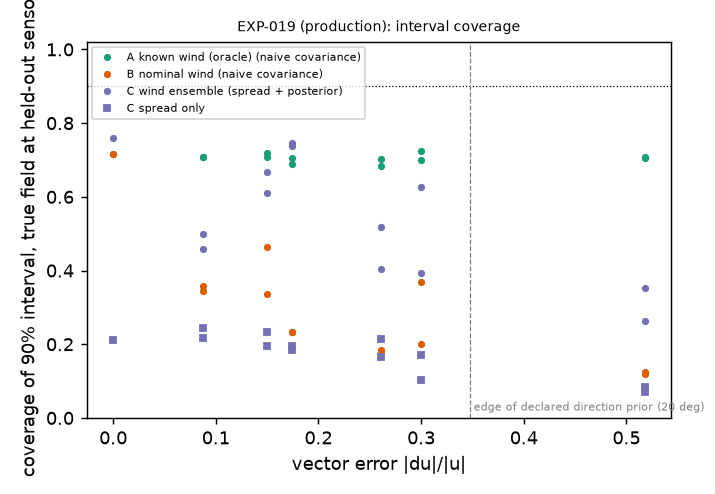

In [12]:
show(T.parent / "figures" / "coverage_vs_vector_error.png", 700)

**Reading (F-029).**
* For B, chi2/dof rises with direction error (1.5 at 5 degrees, 4.7 at 15, 13.7 at 30), so it detects the wrong wind. The flagged fraction stays near 0.5 for B, whatever the error. Flags cannot see the wind.
* For A, chi2/dof stays near 1.0, as it should.
* C helps only when the truth is near an ensemble member (10 degrees: chi2/dof 1.01). At 5 and 15 degrees it does not fit (1.3 and 1.2), and at 30 degrees it is 2.5. Intervals are overconfident there (coverage 0.50 at 5 degrees, 0.35 at 30 degrees, against a target of 0.90).
* Detection is possible because amplitudes cannot absorb all of a rotation. The part they absorb looks like a displaced or rescaled source (see `results/phase3-wind-error-toy/production/README.md`, table).

In [13]:
ww = load(T / "posterior_weight_spread.csv")
ww[ww.speed_pct == 0].sort_values("deg")[["deg", "w_max", "n_eff_members"]].reset_index(drop=True)

,deg,w_max,n_eff_members
0,-30,0.8883,1.567
1,-15,0.8368,1.832
2,-10,0.8428,1.808
3,-5,0.8152,1.862
4,0,0.8436,1.77
5,5,0.8184,1.787
6,10,0.8691,1.575
7,15,0.8481,1.564
8,30,0.9221,1.241


### Prior-membership caveat

Strategy C draws its ensemble from a declared set of 15 winds: 5 directions (-20, -10, 0, 10, 20 degrees) times 3 speed factors (0.8, 1.0, 1.2). It is not a 3x3 grid (`freeze.json`).
The true winds at -10, 0 and +10 degrees (speed factor 1.0) are exact members. The other true winds (+-5, +-15, +-30 degrees) are not.
So the good result of C at 10 degrees is the member case. Controls with an offset prior grid are the aim of EXP-023 (last section, if its results exist). The benefit of C in the main tables is conditional on a good prior.

## 5. Follow-up: EXP-023 (wind-error controls), if available

In [14]:
X = R / "phase3-wind-error-toy-controls"
prod = sorted(X.glob("production/**/tables/*.csv")) if X.exists() else []   # smoke runs are not results
if prod:
    for f in prod[:6]:
        print("==", f.relative_to(X)); display(pd.read_csv(f).head(8))
    for p in sorted(X.glob("production/**/figures/*.png"))[:4]: show(p, 700)
else:
    print("EXP-023 has no production tables yet (smoke runs only or not in the repository):", X.relative_to(ROOT))

EXP-023 has no production tables yet (smoke runs only or not in the repository): results/phase3-wind-error-toy-controls


## Limitations

* **Inverse crime.** The data are made with the same forward model and mesh that the inversion uses (only the wind differs). Real error would be larger and has other sources (mesh, closure, emissions).
* Prescribed winds. No terrain coupling. A 2-D incompressible stream function is not a realistic near-surface wind.
* Intervals are percentile bootstraps over **32 test cases**, on one toy domain, with one base wind direction. They are not confidence intervals for new scenarios.
* The wind error is a fixed wrong wind for all cases, not a random draw. The result is for those winds.
* Prior-membership caveat (above). Alpha sensitivity, model error at zero wind error and other base directions are review-requested controls that are not done.
* F-031 domain sizes hold for this source geometry and wind speed. They scale with `U T`, not with this value.
* Synthetic only. No real meteorology.

Next: `10_phase3_status_and_next_steps.ipynb`.